# SARIMA — Previsão do Preço Diário do Arroz (Baseline Univariado)

**TCC — Sistemas de Informação | PUCRS**
Bruno Origem Noronha

Este notebook implementa o **SARIMA** em **granularidade diária**, o modelo de referência (*baseline*) do trabalho.
É um modelo **univariado**: prevê o preço do arroz usando **somente o histórico do próprio preço**, sem nenhuma variável externa.

- **Variável alvo (y):** preço diário do arroz em reais (`preco_brl`)
- **Variáveis exógenas:** nenhuma

Por que um *baseline*? Ele estabelece o desempenho mínimo a ser superado. Se um modelo com informações extras
(como o SARIMAX com precipitação, ou os modelos XGBoost e LSTM) não superar o SARIMA, essas informações não estão
agregando poder preditivo.

Para que a comparação com o SARIMAX seja justa, este notebook usa **exatamente** a mesma base de preços, a mesma divisão
cronológica e os mesmos parâmetros. A **única diferença** entre os dois modelos é a ausência da precipitação.

Roteiro:
1. Carregamento, preparação diária e divisão cronológica (treino até 31/12/2025 · teste nos primeiros 30 dias de 2026)
2. Análise de estacionariedade (teste ADF)
3. Ajuste do modelo SARIMA diário
4. Previsão no período de teste e métricas (RMSE, MAE, MAPE)
5. Visualização gráfica, exportação e comparação com o SARIMAX

In [1]:
# Bibliotecas
import os
import warnings
warnings.filterwarnings("ignore")   # esconde avisos internos das bibliotecas, para a saída ficar limpa

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from statsmodels.tsa.stattools import adfuller           # teste de estacionariedade
from statsmodels.tsa.statespace.sarimax import SARIMAX   # usado aqui sem exógenas, ou seja, como SARIMA puro

# Pasta onde salvamos o gráfico e as métricas
PASTA_SAIDA = "outputs"
os.makedirs(PASTA_SAIDA, exist_ok=True)

## 1. Carregamento e preparação diária

### 1.1 Leitura e estrutura do índice temporal

- Lemos o arquivo `preco_arroz_limpo.csv` e usamos a coluna `data` como **índice de tempo**.
- Mantemos **apenas** a coluna `preco_brl`: o modelo é univariado.
- Fixamos a **frequência diária** com `asfreq("D")`. Isso garante um registro para cada dia do calendário e informa ao
  `statsmodels` que a série é diária, o que é necessário para datar corretamente as previsões.
- **Dias sem cotação** (fins de semana, feriados ou falhas de coleta) recebem o **último preço conhecido** (`ffill`).
  É a prática padrão em séries de mercado: sem negociação, o preço de referência continua sendo o último divulgado.

In [2]:
# Lê o CSV, usando a coluna "data" como índice de tempo
arroz = pd.read_csv("../data/processed/preco_arroz_limpo.csv", parse_dates=["data"], index_col="data")

# Série univariada com frequência diária contínua
y = arroz["preco_brl"].asfreq("D")

print(f"Dias sem cotação antes do tratamento: {y.isna().sum()}")
y = y.ffill()   # dias sem cotação recebem o último preço conhecido

print(f"Período total: {y.index[0]:%d/%m/%Y} a {y.index[-1]:%d/%m/%Y} ({len(y)} dias)")
y.head()

Dias sem cotação antes do tratamento: 0
Período total: 02/01/2008 a 20/04/2026 (6684 dias)


data
2008-01-02    23.79
2008-01-03    24.14
2008-01-04    24.23
2008-01-05    24.23
2008-01-06    24.23
Freq: D, Name: preco_brl, dtype: float64

### 1.2 Divisão cronológica: treino vs. teste

Em séries temporais a divisão **nunca é aleatória**: o modelo só pode aprender com o passado e ser avaliado no futuro.
A divisão é **idêntica à do SARIMAX**:

| Conjunto | Período | Justificativa |
|---|---|---|
| **Treino** | início da série até **31/12/2025** | o modelo absorve todo o histórico, incluindo choques profundos como a **pandemia de 2020** e as **enchentes no Rio Grande do Sul em 2024** |
| **Teste** | **01/01/2026 a 30/01/2026** (30 dias) | horizonte de **curto prazo**, coerente com o uso prático de uma previsão diária |

A constante `HORIZONTE` define o tamanho do teste e pode ser ajustada entre 15 e 30 dias (mantendo o mesmo valor no SARIMAX).

In [3]:
FIM_TREINO = "2025-12-31"
HORIZONTE  = 30   # dias de teste no início de 2026 (entre 15 e 30)

y_treino = y.loc[:FIM_TREINO]
y_teste  = y.loc["2026-01-01":].iloc[:HORIZONTE]

print(f"Treino: {len(y_treino)} dias ({y_treino.index[0]:%d/%m/%Y} a {y_treino.index[-1]:%d/%m/%Y})")
print(f"Teste : {len(y_teste)} dias ({y_teste.index[0]:%d/%m/%Y} a {y_teste.index[-1]:%d/%m/%Y})")

Treino: 6574 dias (02/01/2008 a 31/12/2025)
Teste : 30 dias (01/01/2026 a 30/01/2026)


### 1.3 Visão geral da série de treino

Os destaques marcam os dois choques que o treino precisa conter: a **pandemia (2020)** e as **enchentes no RS (abr–jun/2024)**.

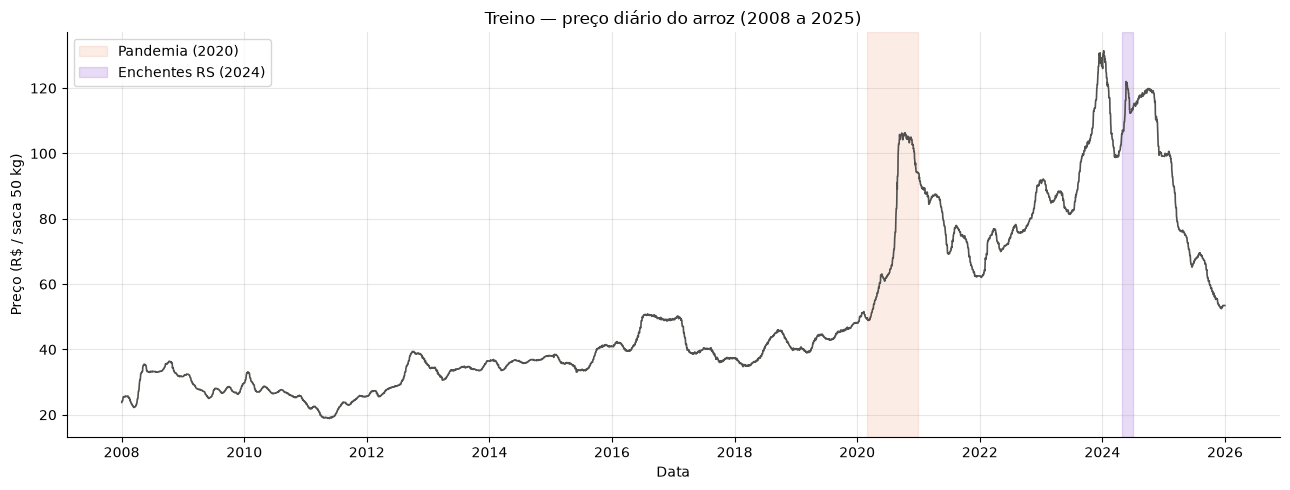

In [4]:
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(y_treino, color="#52514e", lw=1.2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-12-31"), color="#eb6834", alpha=0.12, label="Pandemia (2020)")
ax.axvspan(pd.Timestamp("2024-04-27"), pd.Timestamp("2024-06-30"), color="#7a3cc8", alpha=0.18, label="Enchentes RS (2024)")

ax.set_title("Treino — preço diário do arroz (2008 a 2025)")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. Análise de estacionariedade (teste ADF)

Os modelos ARIMA/SARIMA exigem uma série **estacionária**: média e variância estáveis ao longo do tempo.
O teste **ADF (Augmented Dickey-Fuller)** verifica isso:

- **Hipótese nula (H₀):** a série tem raiz unitária, ou seja, **não é estacionária**.
- **Regra de decisão:** p-valor **< 0,05** → rejeitamos H₀ → a série é estacionária.

Testamos o preço no nível original e na **primeira diferença** (variação de um dia para o outro).
Se o preço só ficar estacionário após diferenciar, usamos **d = 1**.

In [5]:
def teste_adf(s, nome):
    estatistica, p_valor = adfuller(s)[:2]   # 1º item: estatística; 2º item: p-valor
    conclusao = "estacionária" if p_valor < 0.05 else "NÃO estacionária"
    print(f"{nome:<24} ADF = {estatistica:8.3f}   p-valor = {p_valor:.4f}  ->  {conclusao}")

teste_adf(y_treino,                 "Arroz — original")
teste_adf(y_treino.diff().dropna(), "Arroz — 1ª diferença")

Arroz — original         ADF =   -1.835   p-valor = 0.3634  ->  NÃO estacionária
Arroz — 1ª diferença     ADF =   -9.705   p-valor = 0.0000  ->  estacionária


**Leitura:**

- O **preço original não é estacionário** (p-valor acima de 0,05): ele tem tendência de longo prazo e mudanças de patamar.
- A **primeira diferença é estacionária**, portanto adotamos **d = 1**: o modelo trabalha com as **variações diárias** do preço.

### 2.1 Por que sazonalidade semanal (s = 7)?

Com dados diários, o período sazonal `s` precisa refletir um ciclo real e computacionalmente viável:

- **s = 365 (anual)** tornaria o modelo inviável: o espaço de estados teria centenas de dimensões e o ajuste levaria horas, com alto risco de não convergir.
- **s = 7 (semanal)** captura um padrão concreto da série: **não há pregão aos sábados e domingos**, então o preço é repetido nesses dias
  e a variação diária é sempre zero. A tabela abaixo comprova isso.

In [6]:
variacao = y_treino.diff().dropna()
dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]

pd.DataFrame({
    "% de dias sem variação": (variacao == 0).groupby(variacao.index.dayofweek).mean().mul(100).round(1).values,
    "Variação absoluta média (R$)": variacao.abs().groupby(variacao.index.dayofweek).mean().round(3).values,
}, index=dias)

,% de dias sem variação,Variação absoluta média (R$)
Segunda,11.6,0.106
Terça,6.1,0.336
Quarta,6.2,0.186
Quinta,7.1,0.188
Sexta,9.7,0.147
Sábado,100.0,0.000
Domingo,100.0,0.000


Sábados e domingos têm **100% dos dias sem variação**: é um ciclo semanal determinístico que o componente sazonal com `s = 7` aprende a reproduzir.

## 3. Ajuste do modelo SARIMA diário

O modelo é **SARIMA(p, d, q)(P, D, Q, s)**. Na biblioteca `statsmodels` ele é ajustado com a classe `SARIMAX`
**sem o argumento `exog`**: sem variáveis exógenas, o SARIMAX se reduz exatamente a um SARIMA univariado.

| Parâmetro | Valor | Significado |
|---|---|---|
| **p** | 1 | usa a variação do **dia anterior** (parte autorregressiva) |
| **d** | 1 | **1 diferenciação** para tornar a série estacionária (resultado do ADF) |
| **q** | 1 | corrige pelo **erro de previsão do dia anterior** (média móvel) |
| **P** | 1 | usa a variação do **mesmo dia da semana anterior** (autorregressivo sazonal) |
| **D** | 0 | sem diferenciação sazonal: a variação diária já é estacionária |
| **Q** | 1 | corrige pelo erro do **mesmo dia da semana anterior** (média móvel sazonal) |
| **s** | 7 | ciclo sazonal **semanal** (dados diários, sem pregão no fim de semana) |

Em notação de operadores, com $B$ sendo o operador de defasagem ($B\,y_t = y_{t-1}$):

$$(1 - \phi_1 B)(1 - \Phi_1 B^{7})\,(1 - B)\,y_t = (1 + \theta_1 B)(1 + \Theta_1 B^{7})\,\varepsilon_t$$

- $(1 - B)\,y_t = y_t - y_{t-1}$ é a variação diária (d = 1);
- $\phi_1$ e $\theta_1$ são os termos AR e MA do dia anterior;
- $\Phi_1$ e $\Theta_1$ são os termos AR e MA sazonais, que olham 7 dias para trás;
- $\varepsilon_t$ é o erro aleatório (ruído branco).

A ordem é **parcimoniosa** (poucos parâmetros) e **idêntica à do SARIMAX**, para que a comparação isole o efeito da precipitação.
O modelo é ajustado **apenas com o treino**. Usamos `maxiter=200` para garantir a convergência do otimizador.

In [7]:
ORDEM         = (1, 1, 1)      # (p, d, q)
ORDEM_SAZONAL = (1, 0, 1, 7)   # (P, D, Q, s)

modelo = SARIMAX(endog=y_treino, order=ORDEM, seasonal_order=ORDEM_SAZONAL)   # sem exog -> SARIMA univariado
resultado = modelo.fit(disp=False, maxiter=200)   # disp=False esconde as mensagens da otimização

print(resultado.summary())
print(f"\nOtimização convergiu: {resultado.mle_retvals['converged']}")

                                     SARIMAX Results                                     
Dep. Variable:                         preco_brl   No. Observations:                 6574
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 7)   Log Likelihood               -1045.814
Date:                           Tue, 27 Oct 2026   AIC                           2101.628
Time:                                   14:35:05   BIC                           2135.582
Sample:                               01-02-2008   HQIC                          2113.365
                                    - 12-31-2025                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9454      0.005    174.730      0.000       0.935       0.956
ma.L1         -0.8697      0.008   -107.932

**Como ler o resumo:**

- **coef / P>|z|:** cada termo (`ar.L1`, `ma.L1`, `ar.S.L7`, `ma.S.L7`) com p-valor abaixo de 0,05 contribui de forma significativa para o modelo.
- **sigma2:** variância do erro, ou seja, o tamanho típico da "surpresa" diária que o modelo não consegue explicar.
- **AIC:** critério de informação; quanto menor, melhor o equilíbrio entre ajuste e número de parâmetros. É útil para comparar com o SARIMAX.
- **Ljung-Box (Prob(Q)):** acima de 0,05 indica que os resíduos não têm autocorrelação, ou seja, o modelo capturou a dependência temporal.

## 4. Previsão no período de teste e métricas

O modelo prevê os **30 dias de janeiro de 2026 de uma só vez**, sem ter visto o preço do arroz nesse período (*out-of-sample*).
Como é univariado, basta informar o número de passos (`steps`): não há valores futuros de variáveis externas a fornecer.

As métricas são calculadas **manualmente com `numpy`**, a partir das fórmulas, sendo $y_t$ o preço real, $\hat{y}_t$ o previsto e $n$ o número de dias:

| Métrica | Fórmula | O que mede |
|---|---|---|
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_t - \hat{y}_t)^2}$ | erro em R\$; pune mais os erros grandes |
| **MAE** | $\frac{1}{n}\sum \lvert y_t - \hat{y}_t \rvert$ | "em média, erramos X reais por dia" |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{y_t - \hat{y}_t}{y_t} \right\rvert$ | "em média, erramos X% do preço" |

In [8]:
# Previsão para os dias do teste
previsao  = resultado.get_forecast(steps=len(y_teste))
y_prev    = previsao.predicted_mean
intervalo = previsao.conf_int(alpha=0.05)   # limites inferior e superior (95%)

# Métricas calculadas diretamente pelas fórmulas
erro = y_teste.values - y_prev.values
rmse = np.sqrt(np.mean(erro ** 2))
mae  = np.mean(np.abs(erro))
mape = np.mean(np.abs(erro / y_teste.values)) * 100

print(f"RMSE = R$ {rmse:.2f}")
print(f"MAE  = R$ {mae:.2f}")
print(f"MAPE = {mape:.2f}%")

RMSE = R$ 0.37
MAE  = R$ 0.30
MAPE = 0.56%


Tabela dia a dia do período de teste, para inspecionar onde o modelo acerta e erra:

In [9]:
comparacao = pd.DataFrame({
    "Real (R$)":     y_teste,
    "Previsto (R$)": y_prev,
    "Erro (R$)":     y_teste - y_prev,
}).round(2)
comparacao.index = comparacao.index.strftime("%d/%m/%Y")
comparacao

,Real (R$),Previsto (R$),Erro (R$)
01/01/2026,53.45,53.45,-0.00
02/01/2026,53.45,53.50,-0.05
03/01/2026,53.45,53.50,-0.05
04/01/2026,53.45,53.51,-0.06
05/01/2026,53.36,53.52,-0.16
06/01/2026,53.29,53.53,-0.24
07/01/2026,53.31,53.52,-0.21
08/01/2026,53.24,53.53,-0.29
09/01/2026,53.16,53.56,-0.40
10/01/2026,53.16,53.56,-0.40


## 5. Visualização gráfica, exportação e comparação

### 5.1 Gráfico: Real vs. Previsão SARIMA diário

Para dar contexto, exibimos os últimos 90 dias do treino seguidos dos 30 dias de teste.
A área sombreada é o **intervalo de confiança de 95%**: ele se alarga com o horizonte porque a incerteza se acumula a cada dia previsto.

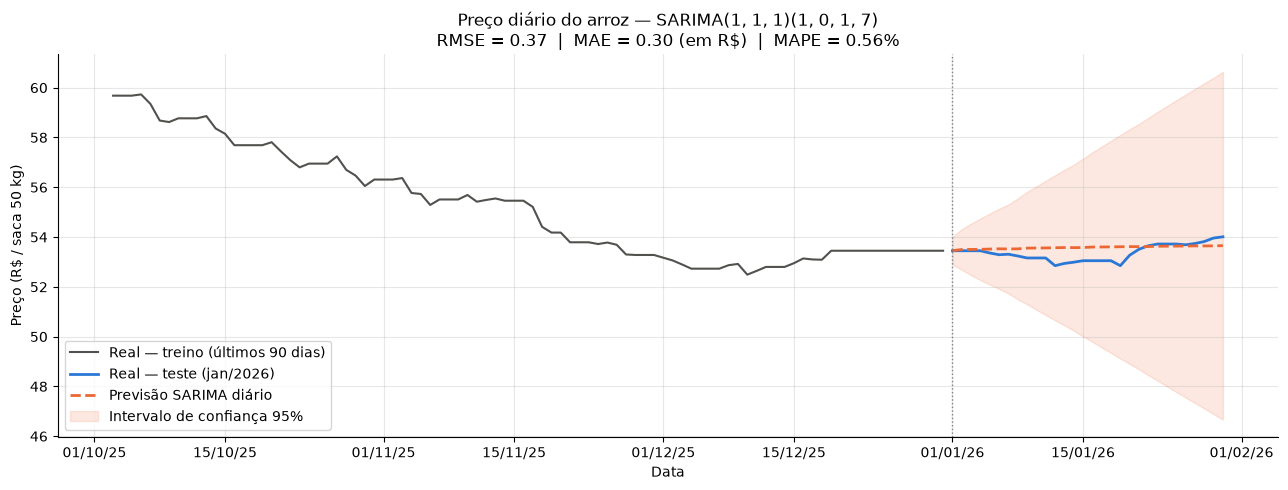

In [10]:
contexto = y_treino.iloc[-90:]   # últimos 90 dias do treino

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(contexto, color="#52514e", lw=1.5, label="Real — treino (últimos 90 dias)")
ax.plot(y_teste,  color="#2a78d6", lw=2,   label="Real — teste (jan/2026)")
ax.plot(y_prev,   color="#eb6834", lw=2, ls="--", label="Previsão SARIMA diário")
ax.fill_between(intervalo.index, intervalo.iloc[:, 0], intervalo.iloc[:, 1],
                color="#eb6834", alpha=0.15, label="Intervalo de confiança 95%")
ax.axvline(y_teste.index[0], color="gray", ls=":", lw=1)   # linha do corte treino/teste

ax.set_title(f"Preço diário do arroz — SARIMA{ORDEM}{ORDEM_SAZONAL}\n"
             f"RMSE = {rmse:.2f}  |  MAE = {mae:.2f} (em R$)  |  MAPE = {mape:.2f}%")
ax.set_xlabel("Data")
ax.set_ylabel("Preço (R$ / saca 50 kg)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower left")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/sarima_previsao.png", dpi=150)
plt.show()

### 5.2 Exportação das métricas

Salvamos as métricas em CSV, no mesmo formato dos demais modelos, para montar a tabela comparativa com SARIMAX, XGBoost e LSTM.

In [11]:
pd.DataFrame({"modelo": ["SARIMA"], "RMSE": [rmse], "MAE": [mae], "MAPE": [mape]}) \
  .round(4).to_csv(f"{PASTA_SAIDA}/metricas_sarima.csv", index=False)

print(f"Gráfico salvo em {PASTA_SAIDA}/sarima_previsao.png")
print(f"Métricas salvas em {PASTA_SAIDA}/metricas_sarima.csv")
pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima.csv")

Gráfico salvo em outputs/sarima_previsao.png
Métricas salvas em outputs/metricas_sarima.csv


,modelo,RMSE,MAE,MAPE
0,SARIMA,0.3722,0.2959,0.5564


### 5.3 Tabela comparativa: SARIMA (baseline) vs. SARIMAX (com precipitação)

Lemos as métricas do SARIMAX diário (geradas pelo notebook `sarimax_arroz.ipynb`, que deve ter sido executado antes)
e colocamos lado a lado. Os dois modelos usam o mesmo treino, o mesmo teste e os mesmos parâmetros, então a diferença
nas métricas se deve **apenas à precipitação**.

Nas três métricas, **quanto menor, melhor**. A última linha mostra a **variação percentual** do SARIMAX em relação ao SARIMA:
valores **negativos** significam que a precipitação **reduziu o erro**; positivos, que **aumentou**.

In [12]:
sarima  = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarima.csv")
sarimax = pd.read_csv(f"{PASTA_SAIDA}/metricas_sarimax.csv")

tabela = pd.concat([sarima, sarimax]).set_index("modelo")
tabela.index = ["SARIMA (baseline)", "SARIMAX (com precipitação)"]

# Variação % do SARIMAX em relação ao SARIMA
tabela.loc["Variação (%)"] = (tabela.iloc[1] / tabela.iloc[0] - 1) * 100

tabela.round(4)

,RMSE,MAE,MAPE
SARIMA (baseline),0.3722,0.2959,0.5564
SARIMAX (com precipitação),0.3718,0.2957,0.5560
Variação (%),-0.1075,-0.0676,-0.0719


## Conclusão

- **Ajuste:** o otimizador convergiu e todos os termos (AR e MA, não sazonais e semanais) foram altamente significativos,
  confirmando a dependência de curto prazo e o ciclo semanal do preço diário. O teste de Ljung-Box (Prob(Q) alto) indica que
  não sobrou autocorrelação relevante nos resíduos.
- **Previsão:** no horizonte de 30 dias de janeiro de 2026, o SARIMA errou em média cerca de **R\$ 0,30 por saca (MAPE ≈ 0,6%)**.
  O valor baixo reflete, em grande parte, a **inércia do preço diário**: de um dia para o outro o preço muda pouco.
- **SARIMA vs. SARIMAX:** as métricas dos dois modelos são **praticamente idênticas** (diferença de cerca de 0,1%), e o AIC do SARIMA
  (≈ 2.101,6) é até **menor** que o do SARIMAX (≈ 2.103,4), ou seja, o parâmetro extra da precipitação não compensa sua complexidade.
  Somado ao coeficiente não significativo da chuva no SARIMAX, isso indica que a **precipitação do mesmo dia não agrega poder preditivo**
  à série diária do preço do arroz.
- **Limitações:** o resumo do modelo mostra **heterocedasticidade** (H elevado) e **caudas pesadas** (curtose alta), herança de choques
  como a pandemia e as enchentes de 2024. O intervalo de confiança deve, portanto, ser lido com cautela.
- **Papel no trabalho:** o SARIMA diário fica estabelecido como **baseline**. Os próximos modelos (XGBoost e LSTM) precisam superar
  estas métricas para justificar sua complexidade adicional.